Random Forest Regressor

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestRegressor

df = pd.read_csv("/Applications/MAMP/htdocs/local/kodingakademi/Python/bootcamp data analis/pertemuan/ML/death_clean.csv")
df.head()

,Cause,Type,Year,Data Redundancy,Total Deaths,Source,Page at Source,Source URL
0,Abrasi Air Laut,Bencana Alam,2012,1,0,Profil Kesehatan Indonesia Tahun 2012,Lampiran 3.38,https://pusdatin.kemkes.go.id/download.php?fil...
1,AIDS,Bencana Non Alam dan Penyakit,2000,1,47,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
2,AIDS,Bencana Non Alam dan Penyakit,2001,1,99,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
3,AIDS,Bencana Non Alam dan Penyakit,2002,1,100,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
4,AIDS,Bencana Non Alam dan Penyakit,2003,1,261,Profil Kesehatan Indonesia Tahun 2010,115,https://pusdatin.kemkes.go.id/download.php?fil...


In [3]:
x = df[["Cause", "Type"]]
y = df[["Total Deaths"]]

x_encode = pd.get_dummies(x, columns=["Cause", "Type"])

scale = MinMaxScaler()
y_norm = scale.fit_transform(y).ravel()

x_train, x_test, y_train, y_test = train_test_split(x_encode, y_norm, test_size=0.3, random_state=42)

print(f"x_train = {len(x_train)}, x_test = {len(x_test)}")
print(f"y_train = {len(y_train)}, y_test = {len(y_test)}")

x_train = 385, x_test = 165
y_train = 385, y_test = 165


In [4]:
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(x_train, y_train)

y_pred = model.predict(x_test)
y_pred

array([1.25279078e-01, 7.52600964e-02, 3.00020092e-02, 6.08771354e-02,
       1.13331298e-01, 1.13331298e-01, 7.52600964e-02, 6.27106914e-04,
       7.70852518e-03, 2.21940928e-02, 8.43881857e-05, 6.07668127e-01,
       7.52600964e-02, 1.48973277e-01, 3.87408345e-01, 7.52600964e-02,
       6.27106914e-04, 6.07668127e-01, 9.28914674e-03, 2.72411314e-02,
       2.84106892e-02, 1.82869198e-01, 1.95937312e-01, 1.24034808e-02,
       7.52600964e-02, 9.06391624e-05, 8.43881857e-05, 2.88788204e-02,
       1.03427489e-01, 1.03427489e-01, 1.13130149e-02, 2.10970464e-04,
       6.27106914e-04, 7.52600964e-02, 3.35240991e-02, 7.52600964e-02,
       6.07668127e-01, 1.82869198e-01, 8.47452448e-02, 8.47452448e-02,
       1.25279078e-01, 7.03234880e-05, 1.06891702e-02, 7.52600964e-02,
       3.35240991e-02, 2.36821378e-01, 1.13331298e-01, 1.03427489e-01,
       2.41544803e-02, 1.03427489e-01, 2.84106892e-02, 2.11661463e-02,
       7.03234880e-05, 6.27106914e-04, 1.23850324e-02, 2.33065908e-03,
      

In [5]:
y_test_orig = scale.inverse_transform(y_test.reshape(-1,1)).ravel()
y_pred_orig = scale.inverse_transform(y_pred.reshape(-1,1)).ravel()

result = pd.DataFrame({
    "Aktual" : y_test_orig,
    "Prediksi" : y_pred_orig
})

result

,Aktual,Prediksi
0,99.0,89.073424
1,35.0,53.509929
2,34.0,21.331429
3,49.0,43.283643
4,42.0,80.578553
...,...,...
160,129.0,211.251387
161,184.0,127.182364
162,0.0,1.925865
163,0.0,13.949828


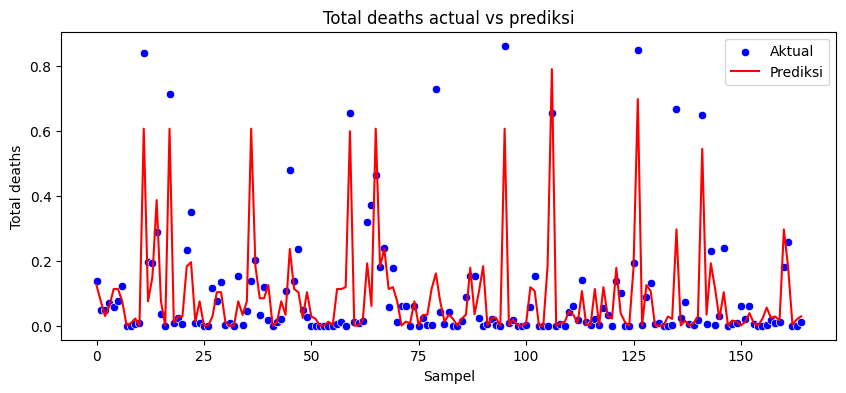

In [6]:
plt.figure(figsize=(10,4))
sns.scatterplot(x = range(len(y_test)), y = y_test, label = "Aktual", color = "blue")
sns.lineplot(x = range(len(y_pred)), y = y_pred, label = "Prediksi", color = "red")
plt.xlabel("Sampel")
plt.ylabel("Total deaths")
plt.title("Total deaths actual vs prediksi")
plt.legend()
plt.show()

In [7]:
score = model.score(x_test, y_test)
print(f"skor = {score}")

skor = 0.726078755783095


In [8]:
import graphviz
from io import StringIO
from sklearn.tree import export_graphviz
import os

x_encode.columns = x_encode.columns.str.replace('[^a-zA-Z0-9]', '_', regex=True)

output_dir = '/Applications/MAMP/htdocs/local/kodingakademi/Python/bootcamp data analis/pertemuan/ML/tree_pdf'

os.makedirs(output_dir, exist_ok=True)

for i, tree in enumerate(model.estimators_):
    dot_data = StringIO()
    export_graphviz(tree, out_file=dot_data, 
                    feature_names=x_encode.columns,
                    filled=True, rounded=True, special_characters=False)
    
    graph = graphviz.Source(dot_data.getvalue())
    tree_filename = os.path.join(output_dir, f"decision_tree_{i}")
    graph.render(tree_filename, format='pdf')

Random Forest Classifier

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier

data = pd.read_csv("/Applications/MAMP/htdocs/local/kodingakademi/Python/bootcamp data analis/pertemuan/ML/penyakit_jantung.csv")
data

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,female,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,female,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,male,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,female,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,male,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,male,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,female,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,female,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,female,0,130,131,0,1,115,1,1.2,1,1,3,0


In [10]:
x = data.drop(columns=["target"])
y = data["target"] 

x_encode = pd.get_dummies(x, columns=["sex"], drop_first=True)

x_train, x_test, y_train, y_test = train_test_split(x_encode, y, test_size=0.3, random_state=42)

print(f"x_train = {len(x_train)}, x_test = {len(x_test)}")
print(f"y_train = {len(y_train)}, y_test = {len(y_test)}")

x_train = 212, x_test = 91
y_train = 212, y_test = 91


In [11]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(x_train, y_train)

y_pred = model.predict(x_test)
y_pred

array([0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0,
       0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1,
       0, 0, 1])

In [12]:
result_df = pd.DataFrame({
    "Actual" : y_test.values,
    "Prediksi" : y_pred
})

result_df

,Actual,Prediksi
0,0,0
1,0,1
2,1,1
3,0,0
4,1,1
...,...,...
86,0,0
87,1,1
88,1,0
89,1,0


In [13]:
score = model.score(x_test, y_test)
print(f"skor = {score:.2f}")

skor = 0.81


ASSIGNMENT

In [31]:
bank = pd.read_csv("/Applications/MAMP/htdocs/local/kodingakademi/Python/bootcamp data analis/pertemuan/ML/bank_customer.csv")
bank

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42.0,2,0.00,1,1.0,1.0,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41.0,1,83807.86,1,0.0,1.0,112542.58,0
2,3,15619304,Onio,502,France,Female,42.0,8,159660.80,3,1.0,0.0,113931.57,1
3,4,15701354,Boni,699,France,Female,39.0,1,0.00,2,0.0,0.0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43.0,2,125510.82,1,NaN,1.0,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9997,9998,15584532,Liu,709,France,Female,36.0,7,0.00,1,0.0,1.0,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42.0,3,75075.31,2,1.0,0.0,92888.52,1
9999,9999,15682355,Sabbatini,772,Germany,Male,42.0,3,75075.31,2,1.0,0.0,92888.52,1
10000,10000,15628319,Walker,792,France,Female,28.0,4,130142.79,1,1.0,0.0,38190.78,0


In [32]:
bank.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          1
Gender             0
Age                1
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          1
IsActiveMember     1
EstimatedSalary    0
Exited             0
dtype: int64

In [33]:
bank.fillna(0, inplace = True)

In [34]:
bank.drop_duplicates(inplace= True)

In [35]:
q1 = bank["Balance"].quantile(0.25)
q3 = bank["Balance"].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

df_clean = bank[(bank["Balance"] >= lower) & (bank["Balance"]<= upper)]
df_clean

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42.0,2,0.00,1,1.0,1.0,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41.0,1,83807.86,1,0.0,1.0,112542.58,0
2,3,15619304,Onio,502,France,Female,42.0,8,159660.80,3,1.0,0.0,113931.57,1
3,4,15701354,Boni,699,France,Female,39.0,1,0.00,2,0.0,0.0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43.0,2,125510.82,1,0.0,1.0,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39.0,5,0.00,2,1.0,0.0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35.0,10,57369.61,1,1.0,1.0,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36.0,7,0.00,1,0.0,1.0,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42.0,3,75075.31,2,1.0,0.0,92888.52,1


In [43]:
x = df_clean.drop(columns=["RowNumber", "CustomerId", "Surname", "Exited"])
y = df_clean["Exited"]

x = pd.get_dummies(x, columns=["Geography", "Gender"], drop_first=True)

scale = MinMaxScaler()
x[["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "HasCrCard", "IsActiveMember","EstimatedSalary"]] = scale.fit_transform(x[["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "HasCrCard", "IsActiveMember","EstimatedSalary"]])

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print(f"x_train = {len(x_train)}, x_test = {len(x_test)}")
print(f"y_train = {len(y_train)}, y_test = {len(y_test)}")

x_train = 8000, x_test = 2000
y_train = 8000, y_test = 2000


In [44]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(x_train, y_train)

y_pred = model.predict(x_test)
y_pred

array([0, 0, 0, ..., 1, 0, 0])

In [45]:
score = model.score(x_test, y_test)
score

0.868

In [46]:
result_df = pd.DataFrame({
    "Actual" : y_test.values,
    "Prediksi" : y_pred
})

result_df

,Actual,Prediksi
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
...,...,...
1995,1,1
1996,0,0
1997,1,1
1998,1,0
